# LinearElastic tutorial

This notebook walks through the model step by step: how a sequence defines an elastic network, how ligand binding enters its energy, how the free energy and binding free energies are computed, how folding stability enters through an unfolded state, and how populations evolve under selection for binding. The equations are those of `methods.md`, which describes the model in full.

**Running it.** Start Jupyter from the repository root and pick the Julia kernel; the kernel activates the project there, so `using LinearElastic` loads the code in `src/`. Each section builds on the previous one, so run the cells in order.

## 1. Packages

`LinearElastic` is the model. `PyPlot` (matplotlib) draws the figures, and the rest are Julia standard libraries. Seeding the random number generator makes every random draw below (the network, the sequence, the evolution) reproducible.

In [1]:
using LinearElastic
using PyPlot, Random, LinearAlgebra, Statistics, Printf, LaTeXStrings

Random.seed!(2);   # makes this notebook reproducible

## 2. Model parameters

The model represents a protein as an elastic network of nodes (amino acid residues) at fixed reference positions $\mathbf{R}^0$ in two dimensions: a triangular lattice of `L` columns alternating between `W - 1` and `W` nodes, with each coordinate displaced by Gaussian noise of standard deviation `offset`. Nodes that are nearest neighbors on the lattice are connected by springs.

Each node carries one of $q$ amino acid types. The spring between nodes $i$ and $j$ has a stiffness $k_{ij}(s_i, s_j)$, a rest-length mismatch $d_{ij}(s_i, s_j)$ and a contact energy $\varepsilon_{ij}(s_i, s_j)$, read from three random symmetric $q \times q$ tables `K`, `D` and `E`. `makeTables` draws the geometry and the tables once; they stay fixed while sequences evolve.

In [2]:
W, L = 11, 11              # lattice: L columns alternating W-1 and W nodes (L must be odd)
offset = 0.15              # std of the random displacement of each node (lattice spacing = 1)
N_types = 5                # number of amino acid types, q
k_min, k_max = 1e-2, 1e1   # range of spring stiffnesses (log-uniform)
mismatchVar = 0.1          # std of the rest-length mismatches, σ_D
energyVar = 0.0            # std of the contact energies, σ_ε
β = 1.0                    # inverse temperature

tables = makeTables(W, L, offset, N_types, k_min, k_max, energyVar, mismatchVar)
N = length(tables.R) ÷ 2   # positions are stored as R = [x1, y1, x2, y2, ...]
println("nodes: $N, springs: $(Int(sum(tables.A) / 2)), amino acid types: $N_types")
println("stiffness table K (rows and columns are amino acid types):")
display(round.(tables.K, sigdigits=2))

nodes: 115, springs: 304, amino acid types: 5


stiffness table K (rows and columns are amino acid types):


5×5 Matrix{Float64}:
  0.013  2.3    8.3   0.32   10.0
  2.3    0.029  2.2   0.38    0.018
  8.3    2.2    2.2   0.29    1.8
  0.32   0.38   0.29  8.6     0.042
 10.0    0.018  1.8   0.042   0.01

## 3. Ligands

Ligand binding is a spring of stiffness $\kappa$ between two active-site nodes $b_1, b_2$, whose rest length is offset by $\lambda$. Its energy is $\tfrac{1}{2}\kappa(\mathbf{b}\cdot\mathbf{u} - \lambda)^2$, where $\mathbf{b}\cdot\mathbf{u}$ is the extension of the active site. Different ligands are different values of $\lambda$: $\lambda_0 = 0$ for the solvent, and $\lambda_1 = +\delta$ and $\lambda_2 = -\delta$ for two ligands that pull the active site in opposite directions (ligand 1 favors opening it, ligand 2 closing it).

In code, each state is a `Perturbation(bonds, Δk, Δd)` that adds stiffness `Δk` and rest-length offset `Δd` to the listed node pairs, and `Ligands` holds the solvent state first. The two active-site nodes are next-nearest neighbors, so they are not connected by a spring of the network.

active site connected by a network spring? false

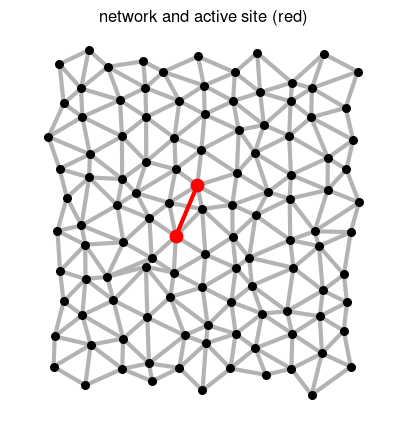

In [3]:
site = (47, 59)    # the two active-site nodes
κ, δ = 1.0, 0.2    # ligand spring stiffness and imposed strain
ligands = Ligands([Perturbation([site], [κ], [0.0]),   # λ0 = 0:  solvent
                   Perturbation([site], [κ], [+δ]),    # λ1 = +δ: ligand 1 opens the site
                   Perturbation([site], [κ], [-δ])])   # λ2 = -δ: ligand 2 closes the site
siteBeads = getSiteBeads(ligands)
println("active site connected by a network spring? ", tables.A[site...] == 1)

xy = reshape(tables.R, 2, :)   # 2 × N matrix of node positions
fig, ax = subplots(figsize=(5, 5))
plotNetwork!(ax, tables.R, tables.A)
ax.plot(xy[1, siteBeads], xy[2, siteBeads], "r-", lw=3, zorder=3)
ax.scatter(xy[1, siteBeads], xy[2, siteBeads], 80, color="r", zorder=4)
ax.set_title("network and active site (red)");

### 3.1 A random sequence

A sequence is a vector of amino acid types, $\mathbf{s} = (s_1, \dots, s_N)$ with $s_i \in \{1, \dots, q\}$. `buildNetwork` turns it into a `Network`, which stores the sequence together with the parameters of its energy (computed once, then updated cheaply after each mutation). Coloring each spring by its stiffness shows how the sequence sets the mechanics of the network.

types of the first 15 nodes: 

[4, 5, 1, 5, 4, 1, 1, 2, 4, 1, 1, 3, 3, 4, 1]


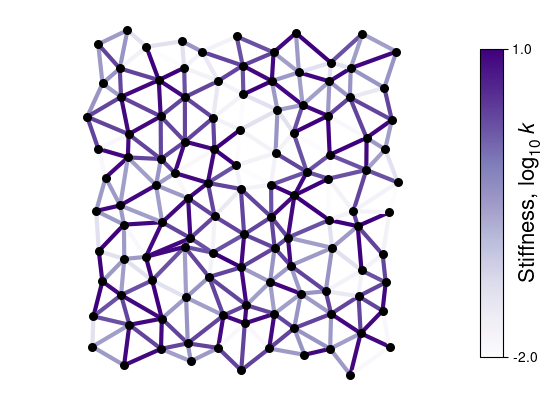

In [4]:
seq = randSeq(tables.R, tables.K)
net = buildNetwork(seq, tables)
println("types of the first 15 nodes: ", seq[1:15])

fig, ax = subplots(figsize=(6, 5))
plotBondStiffness!(ax, fig, net, tables)

### 3.2 The energy landscape

In linear elasticity, the energy of a displacement $\mathbf{u}$ of the nodes from $\mathbf{R}^0$ is a quadratic function,

$$U(\mathbf{u}, \mathbf{s}) = \sum_{\langle ij \rangle} \left[\tfrac{1}{2} k_{ij} (\mathbf{t}_{ij}\cdot\mathbf{u} - d_{ij})^2 + \varepsilon_{ij}\right] = \tfrac{1}{2}\mathbf{u}^\top H \mathbf{u} - \mathbf{h}^\top\mathbf{u} + c,$$

where $\mathbf{t}_{ij}\cdot\mathbf{u}$ is the extension of spring $\langle ij \rangle$. The Hessian $H$ encodes the stiffness, the vector $\mathbf{h}$ the internal stress created by the mismatches, and $c$ is a constant. `seq2NetParams` builds them for the network alone (the ligand spring is added later, as a perturbation). $H$ has three zero modes, the two translations and the rotation of the whole network, which cost no energy.

In [5]:
H, h, c = seq2NetParams(seq, tables)
eigenvalues = eigvals(Symmetric(H))
println("H is $(size(H, 1)) × $(size(H, 2)) (two coordinates per node)")
println("smallest eigenvalues of H: ", round.(eigenvalues[1:5], sigdigits=3))
println("internal stress |h| = ", round(norm(h), sigdigits=3))

H is 230 × 230 (two coordinates per node)
smallest eigenvalues of H: 

[-1.79e-15, 1.25e-15, 1.64e-15, 0.00924, 0.012]
internal stress |h| = 6.6

## 4. Free energy

At inverse temperature $\beta$, integrating the Boltzmann weight $e^{-\beta U}$ over all displacements (except the three zero modes) gives the free energy

$$F(\mathbf{s}, \lambda) = c - \tfrac{1}{2}\mathbf{h}^\top C\,\mathbf{h} + \frac{1}{2\beta}\ln\mathrm{Det}'\!\left(\frac{\beta H}{2\pi}\right),$$

where $C = H^{+}$ is the pseudoinverse of $H$ (the compliance matrix) and $\mathrm{Det}'$ is the product of the nonzero eigenvalues. The first two terms are the energy of the ground state $\mathbf{u}^* = C\mathbf{h}$, and the last is the free energy of thermal fluctuations. The code's constant counts all $2N$ coordinates instead of $2N - 3$, which shifts every free energy by the same amount and cancels in all differences.

`computeFreeEnergy(net, β)` is the free energy of the network without a ligand spring; we check it by hand from $H$, $\mathbf{h}$ and $c$. `computeFreeEnergies` gives $F(\mathbf{s}, \lambda_k)$ for every ligand state.

In [6]:
F = computeFreeEnergy(net, β)
n = length(h)
F_byhand = c - dot(h, pinv(H), h) / 2 - (n * log(2π / β) - sum(log, eigenvalues[4:end])) / (2β)
@printf("F (code) = %.6f,  F (by hand) = %.6f\n", F, F_byhand)

F_states = computeFreeEnergies(net, ligands, tables, β)
@printf("F(s, λ0) = %.6f,  F(s, λ1) = %.6f,  F(s, λ2) = %.6f\n", F_states...)

F (code) = -121.296170,  F (by hand) = -121.296170
F(s, λ0) = -120.755761,  F(s, λ1) = -120.762965,  F(s, λ2) = -120.734788


## 5. Binding free energy

The binding free energy of ligand $k$ is the difference in free energy between ligand-bound and solvent-bound conditions,

$$\Delta F_k(\mathbf{s}) = F(\mathbf{s}, \lambda_k) - F(\mathbf{s}, \lambda_0), \qquad k = 1, 2,$$

and $\Delta F_k < 0$ means the ligand binds. All three states insert the same spring stiffness, so the fluctuation term cancels and the binding energies depend on the sequence only through two properties of the active site in the solvent state: its pre-strain $e_0 = \mathbf{b}^\top C\mathbf{h}$ and its compliance $\chi = \mathbf{b}^\top C\mathbf{b}$, now with $C$ the pseudoinverse of $H + \kappa\mathbf{b}\mathbf{b}^\top$:

$$\Delta F_k = \tfrac{1}{2}\kappa(1 - \kappa\chi)\lambda_k^2 - \kappa\lambda_k e_0.$$

We compute $\Delta F$ with the package and check the closed form.

In [7]:
ΔF = computeBindingEnergies(net, ligands, tables, β)

b = computeBondElongationMode(tables.R, site...)   # unit extension mode of the active site
C = pinv(H + κ * b * b')
e0, χ = dot(b, C, h), dot(b, C, b)
ΔF_closed = [κ * (1 - κ * χ) * λ^2 / 2 - κ * λ * e0 for λ in (+δ, -δ)]

@printf("ΔF1 = %+.5f, ΔF2 = %+.5f  (package)\n", ΔF...)
@printf("ΔF1 = %+.5f, ΔF2 = %+.5f  (closed form, e0 = %+.4f, χ = %.4f)\n", ΔF_closed..., e0, χ)

ΔF1 = -0.00720, ΔF2 = +0.02097  (package)
ΔF1 = -0.00720, ΔF2 = +0.02097  (closed form, e0 = +0.0704, χ = 0.6558)


### 5.1 The binding trade-off

Because $\lambda_2 = -\lambda_1$, the closed form gives $\Delta F_1 + \Delta F_2 = \kappa(1-\kappa\chi)\delta^2 > 0$: no sequence binds both ligands, and binding one more tightly costs binding of the other. Plotting $(-\Delta F_1, -\Delta F_2)$ for 1000 random sequences shows this: every point lies below the dashed diagonal $-\Delta F_1 - \Delta F_2 = 0$. The spread of this cloud, $\Delta F_0$, sets the scale of binding energies and is used below to normalize the strength of selection.

ΔF_0 (spread of random-sequence binding energies) = 0.0086
largest ΔF1 + ΔF2 over random sequences: 0.0333,  smallest: 0.0006


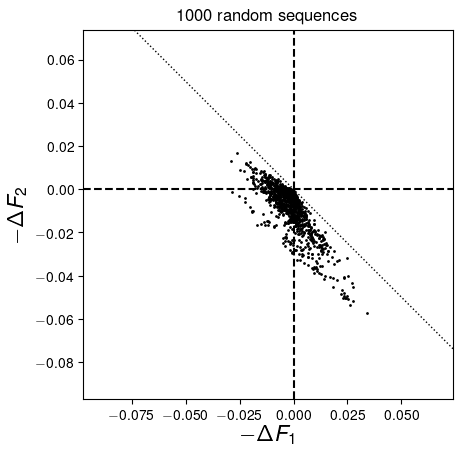

In [8]:
ΔF_rand, ΔF_0, _ = computeBindingRandSeqs(1000, ligands, tables, β)   # (1000 × 2), spread, mean
@printf("ΔF_0 (spread of random-sequence binding energies) = %.4f\n", ΔF_0)
@printf("largest ΔF1 + ΔF2 over random sequences: %.4f,  smallest: %.4f\n",
        maximum(sum(ΔF_rand, dims=2)), minimum(sum(ΔF_rand, dims=2)))

fig = plotDensityBindingSpaceScatter(ΔF_rand)
ax = fig.axes[1]
lim = ax.get_xlim()
ax.plot(lim, -collect(lim), "k:", lw=1)   # -ΔF1 - ΔF2 = 0
ax.set_title("1000 random sequences");

## 6. Mutations change binding

A point mutation replaces the amino acid at node $j$ by type $a$, giving the sequence $\mathbf{s}^{(j \to a)}$. Its effect on binding is

$$\Delta\Delta F_k(j, a) = \Delta F_k(\mathbf{s}^{(j\to a)}) - \Delta F_k(\mathbf{s}).$$

`mutateBead!(net, tables, j, a)` mutates the network in place. It changes only the springs of node $j$, so it updates the stored energy parameters with a low-rank correction instead of rebuilding them; the result is the same as building the mutant from scratch. We compare a mutation next to the active site with one at the far edge of the network, using the number of springs between each node and the active site.

In [9]:
distance = getStepsVector(tables.A, siteBeads)   # springs between each node and the active site
near = findfirst(==(1), distance)
far = findfirst(==(maximum(distance)), distance)

for j in (near, far)
    mutant = deepcopy(net)                        # keep the original network unchanged
    a = mod1(seq[j] + 1, N_types)                 # a different amino acid type
    mutateBead!(mutant, tables, j, a)
    ΔF_mut = computeBindingEnergies(mutant, ligands, tables, β)
    ΔF_fresh = computeBindingEnergies(buildNetwork(mutant.seq, tables), ligands, tables, β)
    ΔΔF = ΔF_mut .- ΔF
    @printf("node %3d (%d springs from the site), type %d -> %d:  ΔΔF1 = %+.2e, ΔΔF2 = %+.2e   (matches a fresh build: %s)\n",
            j, distance[j], seq[j], a, ΔΔF..., ΔF_mut ≈ ΔF_fresh)
end

node  36 (1 springs from the site), type 3 -> 4:  ΔΔF1 = -8.46e-03, ΔΔF2 = +6.03e-03   (matches a fresh build: true)
node  95 (7 springs from the site), type 1 -> 2:  ΔΔF1 = +4.95e-06, ΔΔF2 = -4.93e-06   (matches a fresh build: true)


## 7. Folding

So far every sequence folds into the network. The network can also unfold: we treat folding as an equilibrium between the folded network in solvent, with free energy $F(\mathbf{s}, \lambda_0)$, and an unfolded state whose free energy $F_{\mathrm{u}}$ is the same for every sequence. The fraction of time a sequence spends folded is

$$p_{\mathrm{fold}}(\mathbf{s}) = \frac{1}{1 + e^{\beta (F(\mathbf{s}, \lambda_0) - F_{\mathrm{u}})}},$$

computed by `foldedFraction(F, F_unfolded, β)`. $F_{\mathrm{u}}$ is a physical parameter, passed to the evolution functions as the keyword `F_unfolded` (default `Inf`: nothing unfolds). Here we set it so that only the 10% most stable random sequences fold. Because $\beta = 1$ and free energies of random sequences spread over tens of units, $p_{\mathrm{fold}}$ drops from 1 to 0 within a few units of $F_{\mathrm{u}}$: it acts as a stability threshold.

F(s, λ0) of random sequences: mean -165.5, std 22.9;  F_unfolded = -195.1
mean folded fraction of random sequences: 0.10


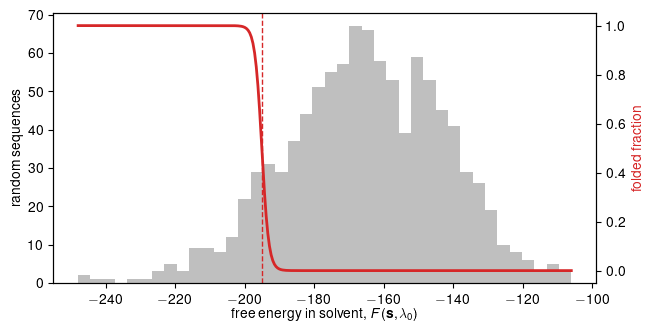

In [10]:
F0_rand = [computeFreeEnergies(buildRandNetwork(tables), ligands, tables, β)[1] for _ in 1:1000]   # F(s, λ0)
F_unfolded = quantile(F0_rand, 0.1)   # only the 10% most stable random sequences fold
@printf("F(s, λ0) of random sequences: mean %.1f, std %.1f;  F_unfolded = %.1f\n", mean(F0_rand), std(F0_rand), F_unfolded)
@printf("mean folded fraction of random sequences: %.2f\n", mean(foldedFraction.(F0_rand, F_unfolded, β)))

fig, ax = subplots(figsize=(7, 3.5))
ax.hist(F0_rand, bins=40, color="0.75")
ax.set_xlabel(L"free energy in solvent, $F(\mathbf{s}, \lambda_0)$")
ax.set_ylabel("random sequences")
ax2 = ax.twinx()
Fgrid = range(extrema(F0_rand)..., length=300)
ax2.plot(Fgrid, foldedFraction.(Fgrid, F_unfolded, β), "C3", lw=2)
ax2.set_ylabel("folded fraction", color="C3")
ax.axvline(F_unfolded, color="C3", ls="--", lw=1);

## 8. Evolution under static selection

A population of $P$ sequences evolves by Wright–Fisher dynamics. Each generation, the next population is drawn from the current one with probabilities

$$p^n \propto p^n_{\mathrm{fold}}\, e^{-a\,\Delta F^n_1/\Delta F_0} = p^n_{\mathrm{fold}}\, e^{\alpha f^n_1},$$

where $f_1 = -\Delta F_1$ is the fitness for binding ligand 1 and $\alpha = a/\Delta F_0$ is the selection strength. Then each amino acid mutates with probability $\mu$. Selection is static: it always acts on ligand 1. (`evolvePop!` instead switches selection between the two ligands every $\tau$ generations.)

`EvoParams(P, N, μ, τ, α)` groups the evolutionary parameters; $\tau$ is not used under static selection. `evolvePopStatic!` evolves a vector of networks in place under a fixed `Assay`, here `Binding1()`, and returns the fitness of every individual at every generation (`fitBucket`, $P \times 1 \times N$), `N_seqs2Keep` individuals sampled at random times from the last half of the run, and the free energy in solvent of every individual at every generation (`F0Bucket`, $P \times N$). We evolve the same initial population twice, with and without the unfolded state.

In [11]:
a = 1.0                                          # selective pressure
evo = EvoParams(100, 1024, 3e-3, 1, a / ΔF_0)    # P, N (generations), μ, τ (unused here), α
initial = [buildRandNetwork(tables) for _ in 1:evo.P]   # random initial population

@time fitBucket, sampled, F0Bucket = evolvePopStatic!(deepcopy(initial), ligands, tables, β, evo, Binding1();
                                                      N_seqs2Keep=100, F_unfolded)
fitBucket_noUnfolding, _, F0Bucket_noUnfolding = evolvePopStatic!(deepcopy(initial), ligands, tables, β, evo, Binding1();
                                                                  N_seqs2Keep=100)   # F_unfolded = Inf
size(fitBucket), size(F0Bucket)

  6.160122 seconds (10.18 M allocations: 1.305 GiB, 9.55% gc time, 32.08% compilation time)


((100, 1, 1024), (100, 1024))

The population mean fitness, in units of $\Delta F_0$, rises as the population adapts to bind ligand 1. Without an unfolded state, selection for binding also makes the network less stable: floppier networks bind better, and most of the population would be unfolded at the threshold (dashed). With the unfolded state, the population first evolves to fold and then improves binding while staying folded, so it binds less tightly: stability and function trade off.

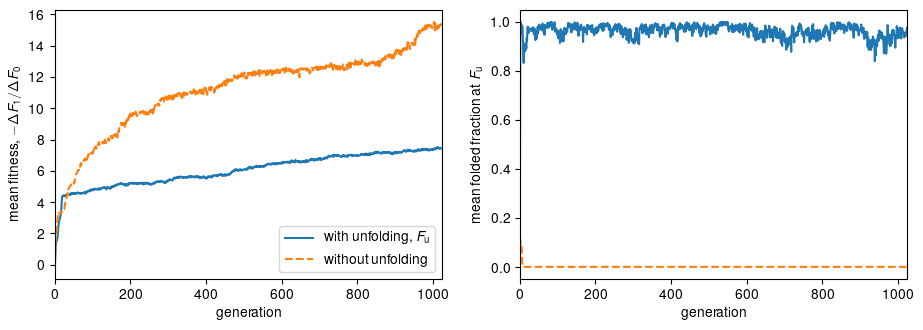

In [12]:
generations = 1:evo.N
meanFitness(fb) = vec(mean(fb[:, 1, :], dims=1)) ./ ΔF_0
meanFolded(F0B) = vec(mean(foldedFraction.(F0B, F_unfolded, β), dims=1))

fig, axs = subplots(1, 2, figsize=(11, 3.5))
axs[1].plot(generations, meanFitness(fitBucket), label=L"with unfolding, $F_{\mathrm{u}}$")
axs[1].plot(generations, meanFitness(fitBucket_noUnfolding), "--", label="without unfolding")
axs[1].set_ylabel(L"mean fitness, $-\Delta F_1 / \Delta F_0$")
axs[2].plot(generations, meanFolded(F0Bucket))
axs[2].plot(generations, meanFolded(F0Bucket_noUnfolding), "--")
axs[2].set_ylabel(L"mean folded fraction at $F_{\mathrm{u}}$")
for ax in axs
    ax.set_xlabel("generation")
    ax.set_xlim(0, evo.N)
end
axs[1].legend(loc="lower right");

For many replicate populations, `evolvePopStaticEnsemble(ligands, tables, β, evo, assay, seeds)` runs one seeded population per seed, in parallel on worker processes when they are available (see `exps/011/scripts/run.jl` for the fluctuating-selection version, `evolvePopEnsemble`).

## 9. The evolved sequences

We compute the binding energies and the folded fraction of the sampled sequences (from the run with unfolding) and compare them with random sequences. The sampled networks carry their cached parameters from the run, so we rebuild each one from its sequence first. The most fit sample is the one with the largest selection weight, $\alpha f_1 + \ln p_{\mathrm{fold}}$: it binds ligand 1 tightly and folds.

most fit sample: ΔF1 = -0.0659 (7.7 ΔF_0), ΔF2 = +0.0906, folded fraction 0.955
samples: mean folded fraction 0.947;  random sequences: 0.104


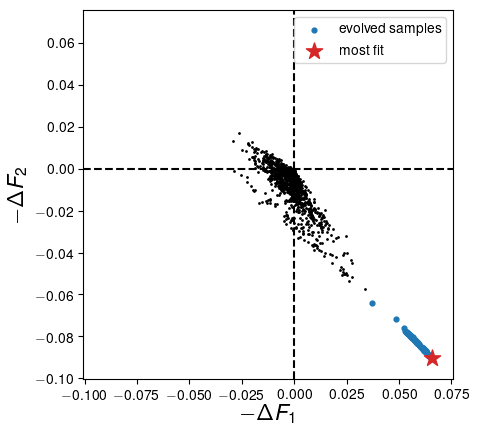

In [13]:
evolvedNets = [buildNetwork(s.seq, tables) for s in sampled]
F_evol = permutedims(hcat([computeFreeEnergies(n, ligands, tables, β) for n in evolvedNets]...))   # samples × 3
ΔF_evol = F_evol[:, 2:3] .- F_evol[:, 1]                                                            # samples × 2
logWeight = evo.α .* (-ΔF_evol[:, 1]) .+ logFoldedFraction.(F_evol[:, 1], F_unfolded, β)
best = argmax(logWeight)
evolved = evolvedNets[best]
@printf("most fit sample: ΔF1 = %+.4f (%.1f ΔF_0), ΔF2 = %+.4f, folded fraction %.3f\n",
        ΔF_evol[best, 1], -ΔF_evol[best, 1] / ΔF_0, ΔF_evol[best, 2], foldedFraction(F_evol[best, 1], F_unfolded, β))
@printf("samples: mean folded fraction %.3f;  random sequences: %.3f\n",
        mean(foldedFraction.(F_evol[:, 1], F_unfolded, β)), mean(foldedFraction.(F0_rand, F_unfolded, β)))

fig = plotDensityBindingSpaceScatter(ΔF_rand)
ax = fig.axes[1]
ax.scatter(-ΔF_evol[:, 1], -ΔF_evol[:, 2], 12, color="C0", label="evolved samples", zorder=3)
ax.scatter(-ΔF_evol[best, 1], -ΔF_evol[best, 2], 150, color="C3", marker="*", label="most fit", zorder=4)
allPoints = [-ΔF_rand; -ΔF_evol]
lo, hi = minimum(allPoints) - 0.01, maximum(allPoints) + 0.01
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.legend(loc="upper right");

## 10. Conformational change on binding

The ground state of the network is $\mathbf{u}^* = C\mathbf{h}$. Binding ligand $k$ changes $\mathbf{h}$ by $\kappa\lambda_k\mathbf{b}$ but not the Hessian, so the conformational change relative to the solvent state is

$$\Delta\mathbf{u}_k = \kappa\lambda_k\, C\,\mathbf{b}:$$

the response of the network to a pair of opposite forces at the active site. The two ligands give the same pattern with opposite signs, and its shape depends on the sequence through $C$. `computeConfChange` returns $\Delta\mathbf{u}_k$ for each ligand. The arrows show the displacement of each node on binding ligand 1, for a random and for the evolved sequence, on a common scale set by the nodes away from the active site (the two active-site nodes move most and get the longest arrows).

random   active site opens by 0.1312; mean displacement of the other nodes 2.85e-02
evolved  active site opens by 0.0764; mean displacement of the other nodes 1.54e-02


ligand 2 gives the opposite displacement: true


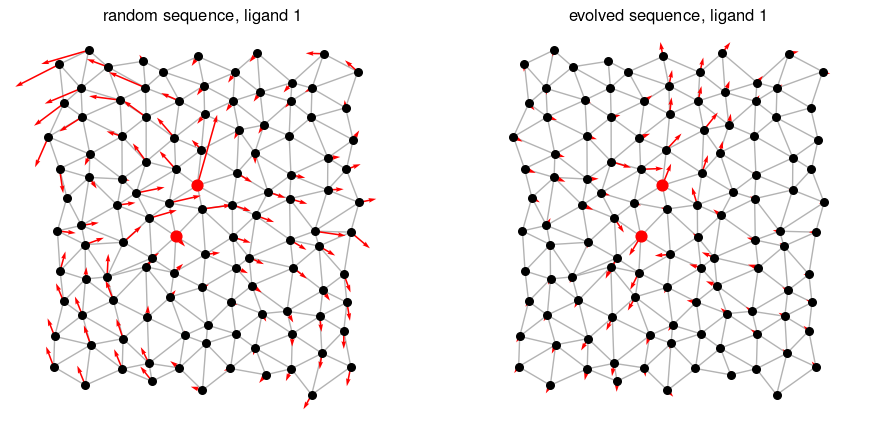

In [14]:
nodeDisplacement(du) = sqrt.(du[1:2:end] .^ 2 .+ du[2:2:end] .^ 2)   # length of each node's displacement

ΔR_rand = computeConfChange(net, ligands, tables)       # columns: ligand 1, ligand 2 (relative to solvent)
ΔR_evol = computeConfChange(evolved, ligands, tables)
offSite = setdiff(1:N, siteBeads)
arrowScale = maximum(maximum(nodeDisplacement(ΔR[:, 1])[offSite]) for ΔR in (ΔR_rand, ΔR_evol)) / 1.5

fig, axs = subplots(1, 2, figsize=(11, 5))
for (ax, ΔR, name) in zip(axs, (ΔR_rand, ΔR_evol), ("random", "evolved"))
    plotNetwork!(ax, tables.R, tables.A; bondWidth=1)
    plotDisplacement!(ax, tables.R, ΔR[:, 1]; scale=arrowScale)
    ax.scatter(xy[1, siteBeads], xy[2, siteBeads], 60, color="r", zorder=4)
    ax.set_title("$name sequence, ligand 1")
    @printf("%-8s active site opens by %.4f; mean displacement of the other nodes %.2e\n",
            name, dot(b, ΔR[:, 1]), mean(nodeDisplacement(ΔR[:, 1])[offSite]))
end
println("ligand 2 gives the opposite displacement: ", ΔR_evol[:, 2] ≈ -ΔR_evol[:, 1])

## 11. Mutational sensitivity

A deep mutational scan computes $\Delta\Delta F_k(j, a)$ for every node $j$, every substitution $a \neq s_j$ and both ligands: `computeBindingDMS` returns an array of size $q \times N \times 2$. The mutational sensitivity of node $j$ is the mean magnitude of these effects,

$$m_j = \frac{1}{2(q-1)}\sum_{k=1}^{2}\sum_{a \neq s_j}\left|\Delta\Delta F_k(j, a)\right|.$$

We map $m_j$ onto the network for the random and the evolved sequence, and plot every mutational effect against the distance of its node from the active site.

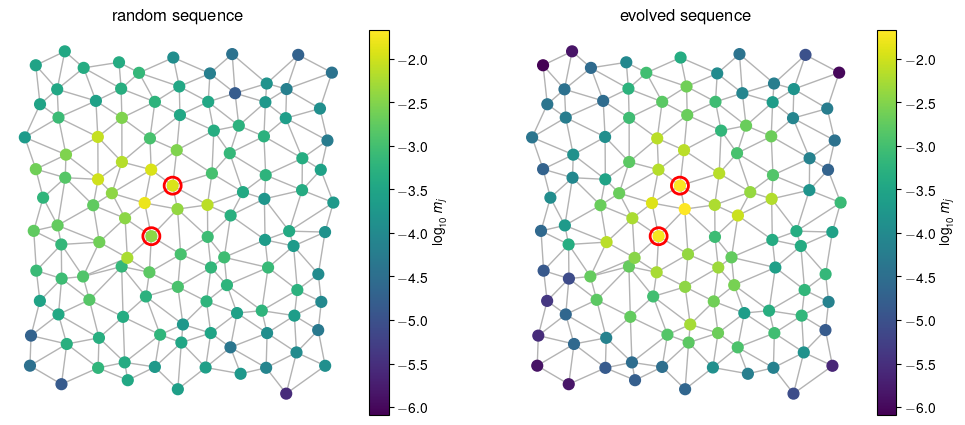

In [15]:
dms_rand = computeBindingDMS(net, ligands, tables, β)
dms_evol = computeBindingDMS(evolved, ligands, tables, β)
positionSensitivity(dms) = [sum(abs, dms[:, j, :]) / (2 * (N_types - 1)) for j in axes(dms, 2)]

m_rand, m_evol = positionSensitivity(dms_rand), positionSensitivity(dms_evol)
vmin, vmax = extrema(log10.([m_rand; m_evol]))
fig, axs = subplots(1, 2, figsize=(12, 5))
for (ax, m, title) in zip(axs, (m_rand, m_evol), ("random sequence", "evolved sequence"))
    plotNetwork!(ax, tables.R, tables.A; bondWidth=1)
    sc = ax.scatter(xy[1, :], xy[2, :], 60, c=log10.(m), cmap="viridis", vmin=vmin, vmax=vmax, zorder=3)
    ax.scatter(xy[1, siteBeads], xy[2, siteBeads], 150, facecolors="none", edgecolors="r", lw=2, zorder=4)
    ax.set_title(title)
    fig.colorbar(sc, ax=ax, label=L"$\log_{10} m_j$")
end

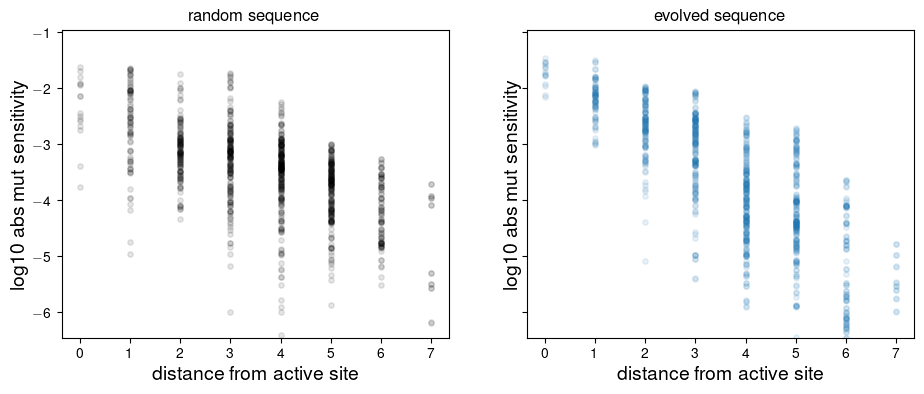

In [16]:
fig, axs = subplots(1, 2, figsize=(11, 4), sharey=true)
plotMutSensVsDist!(axs[1], dms_rand, siteBeads, tables)
plotMutSensVsDist!(axs[2], dms_evol, siteBeads, tables; color="C0")
axs[1].set_title("random sequence")
axs[2].set_title("evolved sequence");

`countMutSensitivity` summarizes a scan. A mutation counts as sensitive if the size of its effect on the two binding energies exceeds a threshold, here the mean effect of mutations next to the active site (`normalizedThresh = 1`). It returns the number of sensitive mutations and positions, the evolvability (root-mean-square effect over all single mutants) and the largest distance from the active site of a sensitive mutation.

In [17]:
@printf("%-10s %14s %14s %14s %14s\n", "", "sens. muts", "sens. sites", "evolvability", "max distance")
for (name, dms) in (("random", dms_rand), ("evolved", dms_evol))
    nm, np, e, md, _ = countMutSensitivity(dms, siteBeads, tables.A, 1.0)
    @printf("%-10s %14d %14d %14.2e %14d\n", name, nm, np, e, md)
end

               sens. muts    sens. sites   evolvability   max distance
random                 42             20       4.86e-03              4


evolved                53             17       6.41e-03              3


## Next steps

- `methods.md` defines the model and the simulation protocol in full.
- `exps/011/scripts` runs ensembles of replicate populations over a range of $\tau$ on a cluster, and `exps/011/analysis/make_figs.jl` analyzes them.
- `test/` checks the physics (`julia --project=. test/test_physics.jl`) and the evolution code.